# 🌿 Crop Disease Detection — CNN Training

This notebook trains a CNN on the **PlantVillage** dataset to classify crop diseases.

**Steps:**
1. Mount Google Drive & install dependencies
2. Download dataset from Kaggle
3. Prepare train / validation / test splits
4. Build & train CNN model (or **resume** from saved checkpoint)
5. Evaluate & save results

> ⚡ **Runtime:** Go to *Runtime → Change runtime type → GPU (T4)* for faster training.

## 1. Setup — Mount Drive & Install Dependencies

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install scikit-learn opendatasets -q

## 2. Configuration

All paths and hyper-parameters are defined here. Edit as needed.

In [3]:
import os, json, random, shutil
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Dense, Dropout,
    BatchNormalization, GlobalAveragePooling2D
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from sklearn.metrics import classification_report

print(f"TensorFlow: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

# ── Paths ──
BASE_DIR    = "/content/drive/MyDrive/CropDiseaseDetection"
DATA_DIR    = os.path.join(BASE_DIR, "data")
TRAIN_DIR   = os.path.join(DATA_DIR, "train")
VAL_DIR     = os.path.join(DATA_DIR, "validation")
TEST_DIR    = os.path.join(DATA_DIR, "test")
MODEL_DIR   = os.path.join(BASE_DIR, "models")
REPORT_DIR  = os.path.join(BASE_DIR, "reports")
MODEL_PATH  = os.path.join(MODEL_DIR, "crop_disease_model.h5")
CLASS_NAMES_PATH = os.path.join(MODEL_DIR, "class_names.json")

# ── Hyper-parameters ──
IMG_SIZE       = 128
BATCH_SIZE     = 32
EPOCHS         = 30
LEARNING_RATE  = 0.001

# Create all output directories
for d in [DATA_DIR, MODEL_DIR, REPORT_DIR]:
    os.makedirs(d, exist_ok=True)

print("Configuration ready ✅")

TensorFlow: 2.20.0
GPU available: False
Configuration ready ✅


## 3. Download & Prepare Dataset

Downloads the PlantVillage dataset from Kaggle using `opendatasets`.

When prompted, enter your **Kaggle credentials**:
- **Username**: your Kaggle username
- **Key**: your Kaggle API key (from [kaggle.com → Settings → API → Create New Token](https://www.kaggle.com/settings))

> ⏭️ This cell **skips** downloading if data already exists on your Drive.

In [4]:
import opendatasets as od

# Check if data already exists
data_ready = (os.path.isdir(TRAIN_DIR) and
              len(os.listdir(TRAIN_DIR)) > 0)

if data_ready:
    print("✅ Dataset already prepared — skipping download.")
else:
    print("📥 Downloading PlantVillage dataset from Kaggle...")
    print("   (Enter your Kaggle username and API key when prompted)\n")

    # Download to Colab local disk (fast)
    od.download("https://www.kaggle.com/datasets/emmarex/plantdisease",
                data_dir="/content")

    # --- Find the extracted folder ---
    source_dir = None
    for candidate in ["/content/plantdisease", "/content/PlantVillage",
                      "/content/plantvillage"]:
        if os.path.isdir(candidate):
            subdirs = [d for d in os.listdir(candidate)
                       if os.path.isdir(os.path.join(candidate, d))]
            if len(subdirs) >= 10:
                source_dir = candidate
                break
            for sub in subdirs:
                deeper = os.path.join(candidate, sub)
                inner = [d for d in os.listdir(deeper)
                         if os.path.isdir(os.path.join(deeper, d))]
                if len(inner) >= 10:
                    source_dir = deeper
                    break
            if source_dir:
                break

    if source_dir is None:
        for item in os.listdir("/content"):
            full = os.path.join("/content", item)
            if os.path.isdir(full):
                children = [d for d in os.listdir(full)
                            if os.path.isdir(os.path.join(full, d))]
                if len(children) >= 10:
                    source_dir = full
                    break

    if source_dir is None:
        print("\n❌ ERROR: Could not find extracted dataset folder!")
        for item in sorted(os.listdir("/content")):
            full = os.path.join("/content", item)
            if os.path.isdir(full):
                print(f"     📁 {item}/ ({len(os.listdir(full))} items)")
        raise FileNotFoundError("Dataset extraction failed.")

    print(f"\n📂 Found dataset at: {source_dir}")

    # --- Split into train/val/test ---
    IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".JPG", ".JPEG", ".PNG"}
    TRAIN_RATIO, VAL_RATIO = 0.80, 0.10
    random.seed(42)

    classes = sorted([d for d in os.listdir(source_dir)
                      if os.path.isdir(os.path.join(source_dir, d))])
    print(f"   Found {len(classes)} classes")

    for split in ["train", "validation", "test"]:
        for cls in classes:
            os.makedirs(os.path.join(DATA_DIR, split, cls), exist_ok=True)

    stats = {"train": 0, "validation": 0, "test": 0}
    for i, cls in enumerate(classes):
        imgs = [f for f in os.listdir(os.path.join(source_dir, cls))
                if Path(f).suffix in IMAGE_EXTS]
        random.shuffle(imgs)
        n = len(imgs)
        n_train = int(n * TRAIN_RATIO)
        n_val = int(n * VAL_RATIO)
        splits = {
            "train": imgs[:n_train],
            "validation": imgs[n_train:n_train+n_val],
            "test": imgs[n_train+n_val:]
        }
        for sname, slist in splits.items():
            for img in slist:
                shutil.copy2(os.path.join(source_dir, cls, img),
                             os.path.join(DATA_DIR, sname, cls, img))
            stats[sname] += len(slist)
        print(f"   [{i+1}/{len(classes)}] {cls}: {n} images", end="\r")

    print(f"\n\n✅ Dataset split complete!")
    print(f"   Train:      {stats['train']} images")
    print(f"   Validation: {stats['validation']} images")
    print(f"   Test:       {stats['test']} images")

✅ Dataset already prepared — skipping download.


### Verify dataset

In [5]:
for name, path in [("Train", TRAIN_DIR), ("Val", VAL_DIR), ("Test", TEST_DIR)]:
    if os.path.isdir(path):
        print(f"{name} classes: {len(os.listdir(path))}")
    else:
        print(f"⚠️ {name} directory NOT found at: {path}")
        print("   → Run the 'Download & Prepare Dataset' cell above first!")

Train classes: 15
Val classes: 15
Test classes: 15


## 4. Data Generators (with augmentation)

In [6]:
train_datagen = ImageDataGenerator(
    rescale=1.0/255, rotation_range=25,
    width_shift_range=0.2, height_shift_range=0.2,
    zoom_range=0.2, horizontal_flip=True,
    brightness_range=[0.8, 1.2], fill_mode='nearest'
)
val_test_datagen = ImageDataGenerator(rescale=1.0/255)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True
)
val_gen = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)
test_gen = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

num_classes = len(train_gen.class_indices)
class_names = [k for k, _ in sorted(train_gen.class_indices.items(), key=lambda x: x[1])]

# Save class name mapping
class_map = {str(v): k for k, v in train_gen.class_indices.items()}
with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_map, f, indent=2)

print(f"\nClasses: {num_classes}")
print(f"Train:   {train_gen.samples}")
print(f"Val:     {val_gen.samples}")
print(f"Test:    {test_gen.samples}")

Found 16504 images belonging to 15 classes.
Found 2058 images belonging to 15 classes.
Found 2076 images belonging to 15 classes.

Classes: 15
Train:   16504
Val:     2058
Test:    2076


### Preview sample images

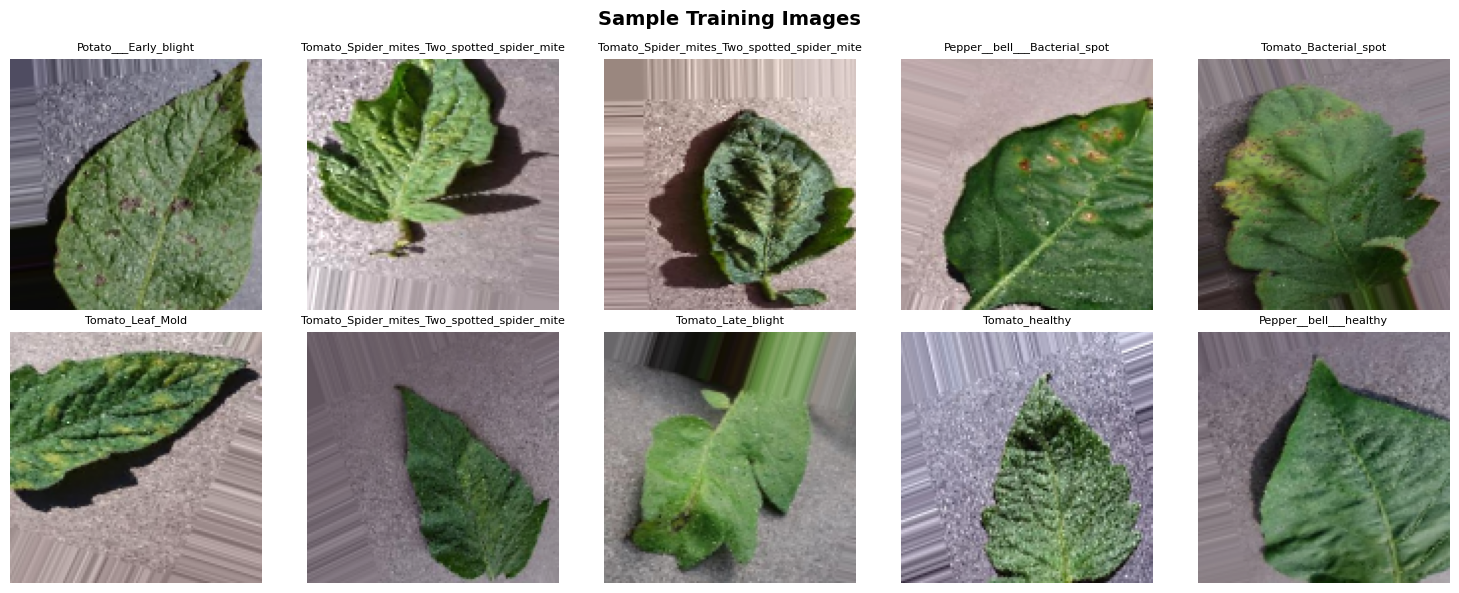

In [7]:
images, labels = next(train_gen)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.set_title(class_names[np.argmax(labels[i])], fontsize=8)
    ax.axis('off')
plt.suptitle('Sample Training Images', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Build or Resume Model

If a saved model exists on Google Drive (from a previous run), it will be **loaded automatically** so you don't lose progress. Otherwise, a new model is built from scratch.

In [8]:
# ── Check for saved model to resume ──
if os.path.exists(MODEL_PATH):
    print(f"📂 Found saved model at: {MODEL_PATH}")
    print("   Loading model to resume training...\n")
    model = load_model(MODEL_PATH)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    print("✅ Model loaded! Will continue training from checkpoint.")
else:
    print("🔨 Building new CNN model...\n")
    model = Sequential([
        # Block 1
        Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(IMG_SIZE,IMG_SIZE,3)),
        BatchNormalization(), Conv2D(32, (3,3), activation='relu', padding='same'),
        BatchNormalization(), MaxPooling2D((2,2)), Dropout(0.25),
        # Block 2
        Conv2D(64, (3,3), activation='relu', padding='same'),
        BatchNormalization(), Conv2D(64, (3,3), activation='relu', padding='same'),
        BatchNormalization(), MaxPooling2D((2,2)), Dropout(0.25),
        # Block 3
        Conv2D(128, (3,3), activation='relu', padding='same'),
        BatchNormalization(), Conv2D(128, (3,3), activation='relu', padding='same'),
        BatchNormalization(), MaxPooling2D((2,2)), Dropout(0.25),
        # Block 4
        Conv2D(256, (3,3), activation='relu', padding='same'),
        BatchNormalization(), MaxPooling2D((2,2)), Dropout(0.25),
        # Head
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'), BatchNormalization(), Dropout(0.5),
        Dense(256, activation='relu'), BatchNormalization(), Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    print("✅ New model built.")

model.summary()

📂 Found saved model at: /content/drive/MyDrive/CropDiseaseDetection/models/crop_disease_model.h5
   Loading model to resume training...



✅ Model loaded! Will continue training from checkpoint.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 854,831 (3.26 MB)

 Trainable params: 851,887 (3.25 MB)

 Non-trainable params: 2,944 (11.50 KB)

## 6. Train Model

If resuming, the model starts with its saved weights and trains for more epochs.

In [9]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1),
    ModelCheckpoint(MODEL_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1)
]

history = model.fit(
    train_gen, epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks, verbose=1
)

Epoch 1/30
 12/516 ━━━━━━━━━━━━━━━━━━━━ 1:03:23 8s/step - accuracy: 0.9546 - loss: 0.1648

KeyboardInterrupt: 

## 7. Evaluate on Test Set

In [ ]:
test_loss, test_accuracy = model.evaluate(test_gen, verbose=1)
print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss:     {test_loss:.4f}")

test_gen.reset()
y_pred = np.argmax(model.predict(test_gen), axis=1)
print("\nClassification Report:")
print(classification_report(test_gen.classes, y_pred, target_names=class_names))

## 8. Training Plots

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(history.history['accuracy'], label='Train', color='#4CAF50', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Val', color='#2196F3', linewidth=2)
ax1.set_title('Accuracy', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'], label='Train', color='#F44336', linewidth=2)
ax2.plot(history.history['val_loss'], label='Val', color='#FF9800', linewidth=2)
ax2.set_title('Loss', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, 'training_curves.png'), dpi=150)
plt.show()
print(f"Plot saved to: {REPORT_DIR}/training_curves.png")

## 9. Done! 🎉

Your trained model and class names are saved to Google Drive.

In [ ]:
print("=" * 50)
print("  Training Complete!")
print("=" * 50)
print(f"  Model:       {MODEL_PATH}")
print(f"  Class names: {CLASS_NAMES_PATH}")
print(f"  Reports:     {REPORT_DIR}")
print(f"  Accuracy:    {test_accuracy*100:.2f}%")
print("=" * 50)
print("\nDownload from Google Drive → CropDiseaseDetection/models/")